In [11]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

In [3]:
processed = Path("../data/processed")
out_dir = Path("../output")

annual = pd.read_csv(processed / "faangm_annual_revenue.csv")
summary = pd.read_csv(processed / "faangm_revenue_summary.csv", index_col="ticker")
scores = pd.read_csv(out_dir / "faangm_quality_scores.csv").sort_values("quality_score").set_index("company")

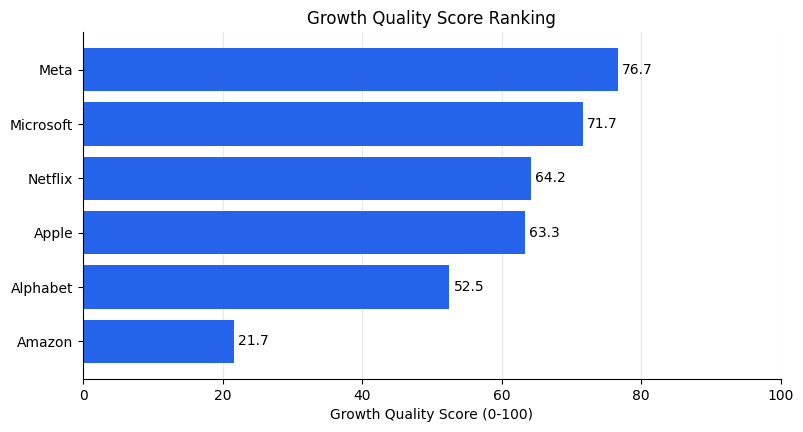

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(scores.index, scores["quality_score"], color="#2563eb")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_xlim(0, 100)
ax.set_xlabel("Growth Quality Score (0-100)")
ax.set_title("Growth Quality Score Ranking")
ax.grid(axis="y", visible=False)
fig.savefig(out_dir / "score_ranking.png", dpi=150, bbox_inches="tight")

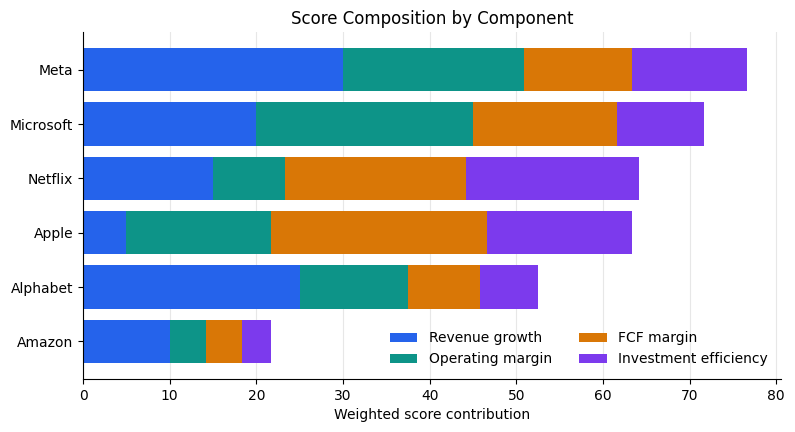

In [15]:
w = json.loads(Path("../config/weights.json").read_text(encoding="utf-8"))
weights = {f"{k}_score": w[k] for k in ["revenue_growth", "operating_margin", "fcf_margin", "investment_efficiency"]}
labels = ["Revenue growth", "Operating margin", "FCF margin", "Investment efficiency"]
colors = ["#2563eb", "#0d9488", "#d97706", "#7c3aed"]

contrib = scores[list(weights)].mul(pd.Series(weights))

fig, ax = plt.subplots(figsize=(9, 4.5))
left = pd.Series(0.0, index=contrib.index)
for col, label, color in zip(contrib.columns, labels, colors):
    ax.barh(contrib.index, contrib[col], left=left, label=label, color=color)
    left += contrib[col]
ax.set_xlabel("Weighted score contribution")
ax.set_title("Score Composition by Component")
ax.grid(axis="y", visible=False)
ax.legend(ncol=2, frameon=False, loc="lower right")
fig.savefig(out_dir / "score_components.png", dpi=150, bbox_inches="tight")

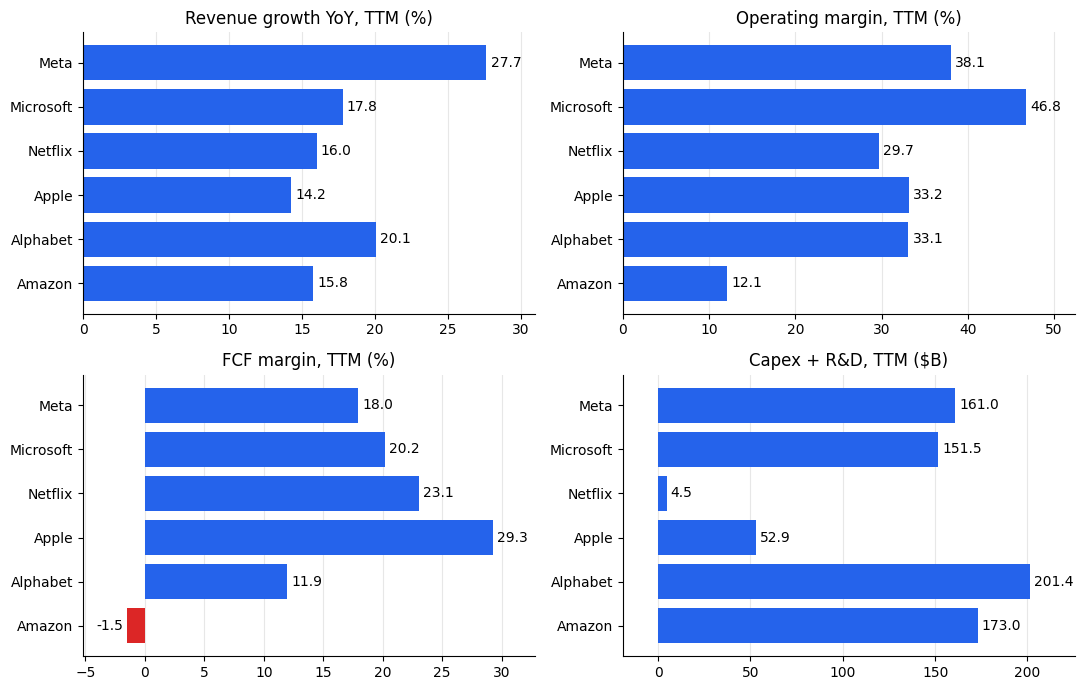

In [10]:
spend = (scores["capex"] + scores["rd"].fillna(0)) / 1e9
panels = [("Revenue growth YoY, TTM (%)", scores["revenue_growth_yoy"] * 100),
          ("Operating margin, TTM (%)", scores["operating_margin"] * 100),
          ("FCF margin, TTM (%)", scores["fcf_margin"] * 100),
          ("Capex + R&D, TTM ($B)", spend)]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (title, s) in zip(axes.flat, panels):
    ax.barh(s.index, s.values, color=["#dc2626" if v < 0 else "#2563eb" for v in s])
    ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
    ax.set_xlim(min(0, s.min() - 0.12 * (s.max() - s.min())), s.max() * 1.12)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(out_dir / "key_metrics.png", dpi=150, bbox_inches="tight")

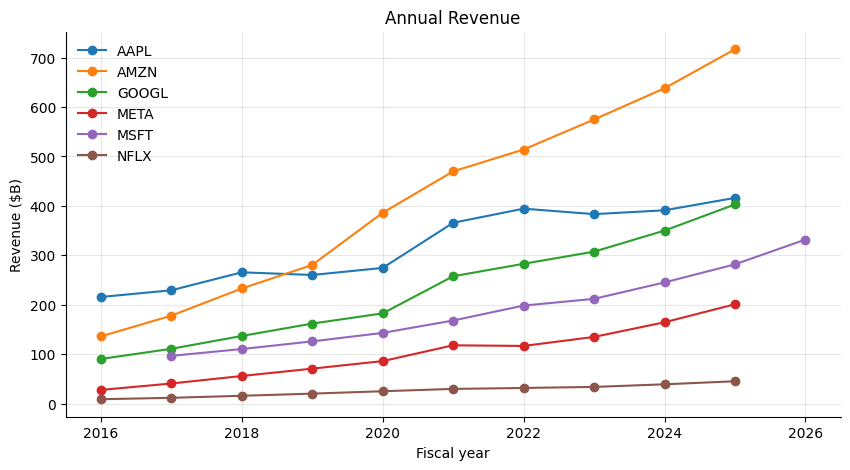

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for ticker, g in annual.groupby("ticker"):
    ax.plot(g["fiscal_year"], g["revenue_billion"], marker="o", label=ticker)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Revenue ($B)")
ax.set_title("Annual Revenue")
ax.legend(frameon=False)
fig.savefig(out_dir / "revenue_trend.png", dpi=150, bbox_inches="tight")

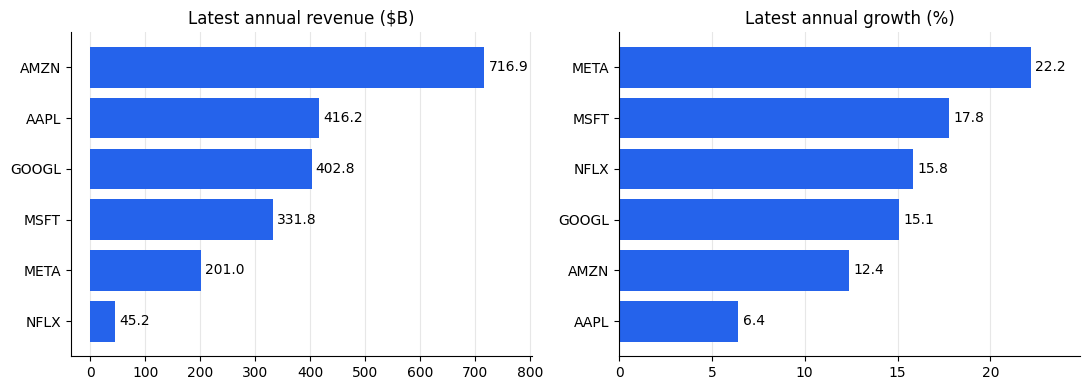

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["revenue", "growth_pct"], ["Latest annual revenue ($B)", "Latest annual growth (%)"]):
    s = summary[col].sort_values()
    ax.barh(s.index, s.values, color=["#dc2626" if v < 0 else "#2563eb" for v in s])
    ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
    ax.set_xlim(min(0, s.min() - 0.12 * (s.max() - s.min())), s.max() * 1.12)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(out_dir / "revenue_latest_growth.png", dpi=150, bbox_inches="tight")